# Visualization & Insights

In this notebook, I will visualize the results of the final restaurant clustering model to communicate the differences between the identified groups more clearly.

I will create visualizations highlighting cluster distribution, numerical characteristics, customer engagement, and cuisine composition.

The objective is to transform the analytical findings into clear visual insights that help explain the restaurant clusters and support the conclusions of the project.

## 1. Imports, Setup & Data Loading

I will import the necessary libraries, establish the project paths, and load the final clustered restaurant dataset.

This dataset will be used throughout this notebook to generate the visualizations and insights.

In [8]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Project Setup 
project_root = Path.cwd().parent
processed_data_path = project_root / "1. data" / "processed"

# Loading Final Clustered Dataset
clustered_restaurants = pd.read_csv(
    processed_data_path / "final_restaurant_clusters.csv"
)
print("Dataset Shape: ", clustered_restaurants.shape)
print("Cluster Counts: ")
display(clustered_restaurants["Clusters"].value_counts().sort_index())


Dataset Shape:  (105, 9)
Cluster Counts: 


Clusters
0    55
1    50
Name: count, dtype: int64

## 2. Cluster Distribution

I will visualize the number of restaurants assigned to each cluster to illustrate the distribution of restaurants across the two groups.

This will provide an overview of the cluster sizes and help determine whether the resulting groups are reasonably balanced.

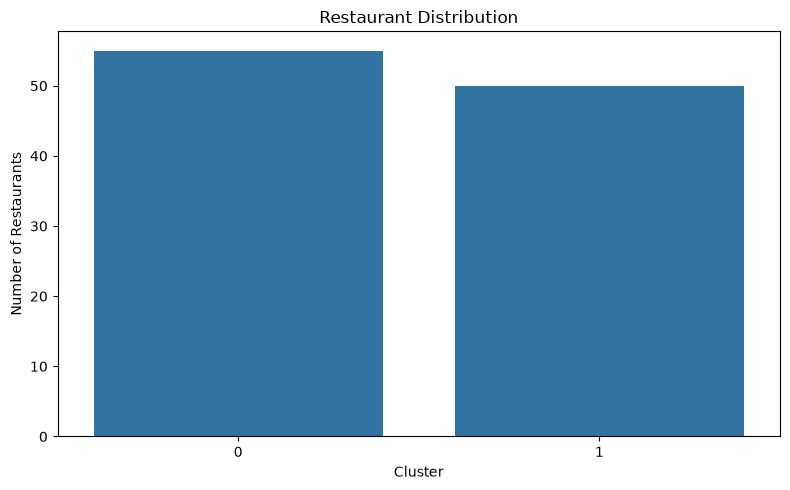

In [9]:
# Cluster Distribution
cluster_counts = clustered_restaurants["Clusters"].value_counts().sort_index()

plt.figure(figsize=(8,5))
sns.barplot(x=cluster_counts.index, y= cluster_counts.values)
plt.title("Restaurant Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of Restaurants")
plt.tight_layout()
plt.show()

## 3. Cost Comparison Across Clusters

I will compare the restaurant costs across the two clusters using a boxplot. This visualization will help identify differences in typical restaurant pricing, the spread of costs, and potential outliers within each cluster.

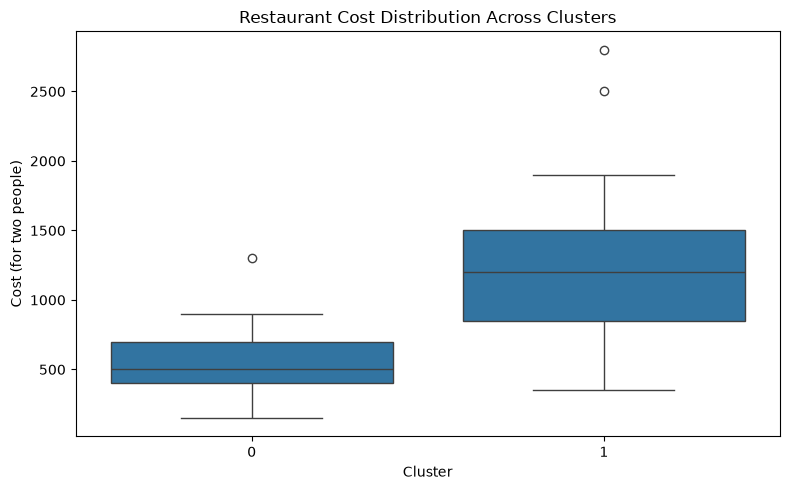

In [10]:
plt.figure(figsize=(8,5))
sns.boxplot(data=clustered_restaurants, x="Clusters", y= "Cost")

# Comparing Restaurant Costs
plt.title("Restaurant Cost Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Cost (for two people)")
plt.tight_layout()
plt.show()

## 4. Rating Comparison Across Clusters

I will compare the average restaurant ratings across the two clusters using a boxplot.

This visualization will help examine the distribution of ratings within each cluster, including their median ratings, variability, and potential outliers.

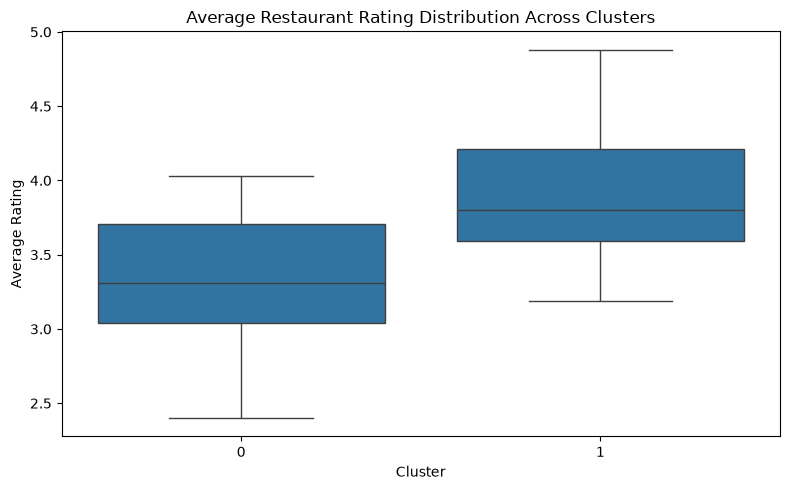

In [11]:
plt.figure(figsize=(8,5))
sns.boxplot(data=clustered_restaurants, x="Clusters", y= "avg_rating")

# Comparing Restaurant Ratings
plt.title("Average Restaurant Rating Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Average Rating")
plt.tight_layout()
plt.show()

## 5. Customer Engagement Comparison

### 5.1 Review Length Comparison

I will compare the median review length across restaurants in the two clusters using a boxplot.

This visualization will help identify differences in the amount of written feedback customers provide and whether customers tend to write longer reviews for restaurants in one cluster compared to the other.

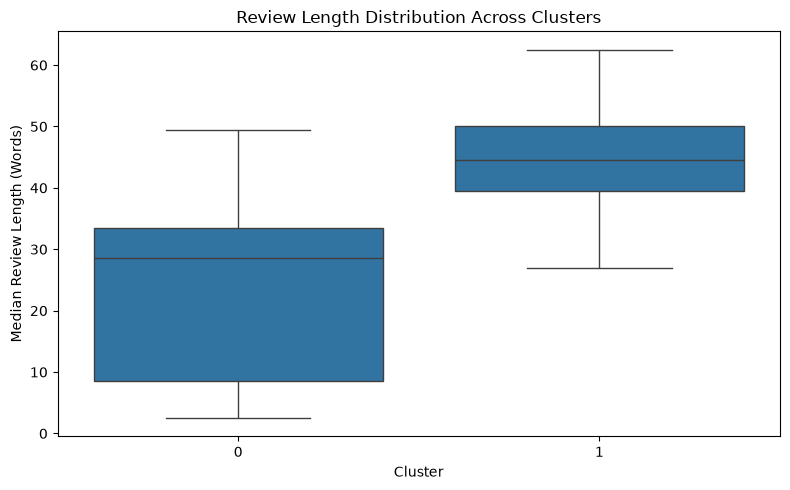

In [12]:
# Comparing Review Length
plt.figure(figsize=(8,5))
sns.boxplot(data=clustered_restaurants, x="Clusters", y = "median_rl")

plt.title("Review Length Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Median Review Length (Words)")
plt.tight_layout()
plt.show()

### 5.2 Picture Engagement Comparison

I will compare the average number of pictures uploaded per review across the two clusters using a boxplot.

This visualization will help examine differences in customer visual engagement and identify whether customers tend to upload more pictures when reviewing restaurants in one cluster compared to the other.

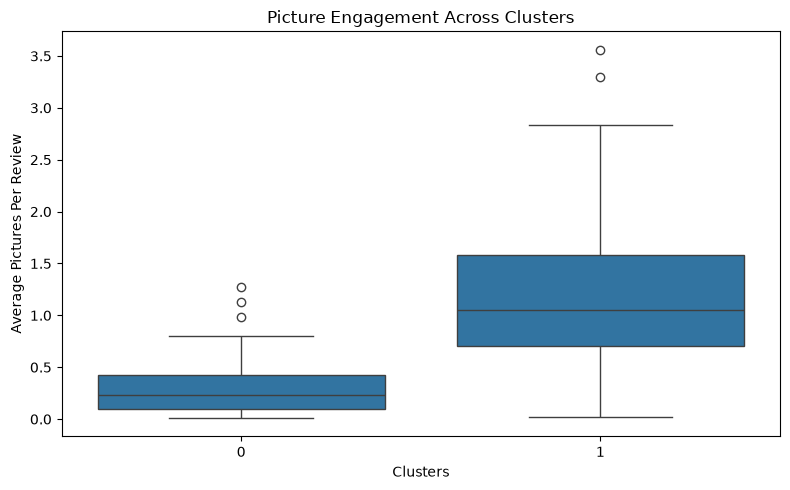

In [13]:
# Comparing Picture Engagement
plt.figure(figsize=(8,5))
sns.boxplot(data=clustered_restaurants, x= "Clusters",y = "avg_pic")

plt.title("Picture Engagement Across Clusters")
plt.xlabel("Clusters")
plt.ylabel("Average Pictures Per Review")

plt.tight_layout()
plt.show()

## 6. Cuisine Composition Across Clusters

I will compare the prevalence of the most common cuisines across the two clusters using a grouped bar chart.

Since restaurants may offer multiple cuisines, the percentages represent the proportion of restaurants within each cluster offering a particular cuisine. This visualization will help identify cuisine similarities and differences between the two groups.

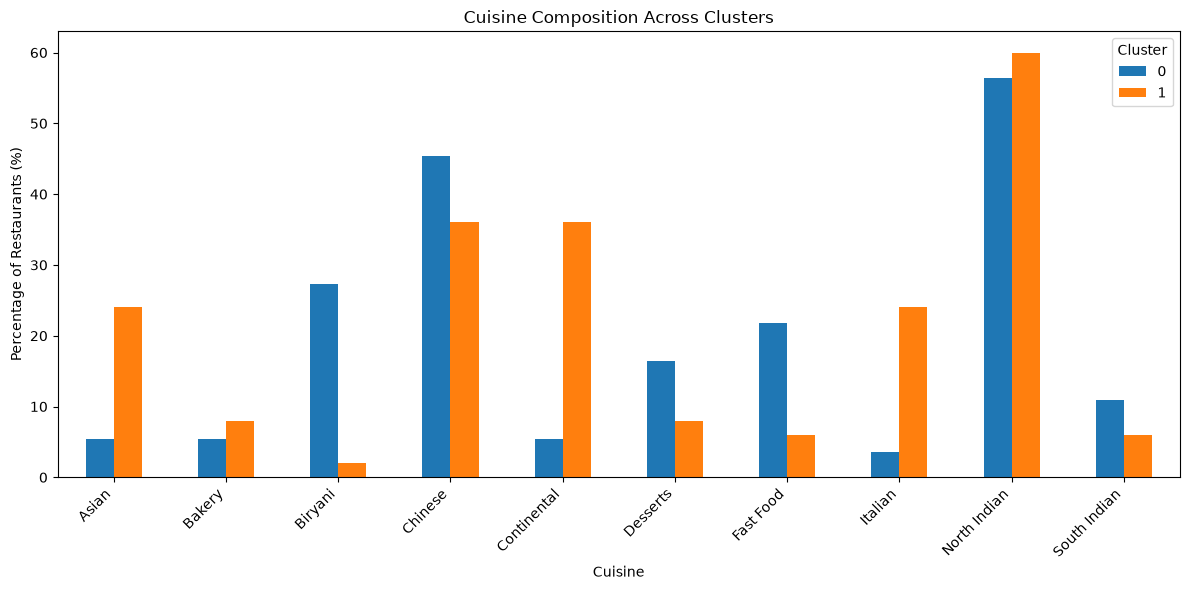

In [14]:
# Comparing Cuisine Composition
cuisine_data = clustered_restaurants[["Clusters", "Cuisines"]].copy()
cuisine_data["Cuisines"]= cuisine_data["Cuisines"].fillna("").str.split(", ")
cuisine_data= cuisine_data.explode("Cuisines")
cuisine_data = cuisine_data[
    cuisine_data["Cuisines"] != ""
]
top_cuisines =cuisine_data["Cuisines"].value_counts().head(10).index
cuisine_data= cuisine_data[
    cuisine_data["Cuisines"].isin(top_cuisines)
]
cuisine_counts = pd.crosstab(
    cuisine_data["Cuisines"],
    cuisine_data["Clusters"]
)
cuisine_percentages = cuisine_counts.div(
    clustered_restaurants.groupby("Clusters").size(),
    axis=1
) *100
cuisine_percentages.plot(
    kind="bar",
    figsize= (12,6) 
)

plt.title("Cuisine Composition Across Clusters")
plt.xlabel("Cuisine")
plt.ylabel("Percentage of Restaurants (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## 7. Summary of Visual Insights

The visualizations provide a clearer understanding of the characteristics of the two restaurant clusters identified by the K-Means clustering model.

**Cluster 0** consists primarily of relatively affordable restaurants with lower average ratings, greater rating variability, shorter customer reviews, and lower picture engagement. Its cuisine composition has a stronger representation of Biriyani, Chinese, Fast Food, Desserts, and South Indian cuisines.

**Cluster 1** consists of relatively expensive restaurants with higher average ratings, more consistent ratings, longer customer reviews, and significantly greater picture engagement. It has a stronger representation of Continental, Italian, and Asian cuisines.

Both clusters have a substantial representation of North Indian cuisine, indicating that cuisine categories overlap between the two groups.

Overall, the visual analysis demonstrates that the clusters differ across multiple dimensions, including pricing, customer ratings, review characteristics, picture engagement, and cuisine composition. These combined characteristics provide a more meaningful understanding of the restaurant groups than any single feature alone.